# Milestone 2: Modeling and Evaluation
## Predicting Potentially Hazardous Asteroids (NASA JPL Asteroid Dataset)

Team 1 | Members: Samuel T, Ishita C, Sebastian A | CAI 4105 Machine Learning, Fall 2026

This notebook continues `Team1_Project_Milestone1.ipynb` (EDA). It prepares the data, engineers features, trains and tunes
seven classifiers, picks a decision threshold, evaluates the chosen model once on a held-out test set, and explains what
the model learned.

**Design recap.** NASA labels an asteroid hazardous (PHA) when MOID ≤ 0.05 AU and H ≤ 22. A model given `moid` and `H` just
re-learns that rule, so the **primary model is leakage-controlled**: it never sees `moid`, `moid_ld`, `H` or `diameter`.
A **reference model** that does see them is trained only for comparison.

**Run time.** About 25 to 35 minutes on a 2-core laptop. Every random step uses `RANDOM_STATE = 42`.

| Section | Team lead (review and presentation) |
|---|---|
| 1–4 Data preparation, feature engineering, split | Samuel T, Ishita C |
| 6 Majority baseline, logistic regression, LDA | Samuel T |
| 7 QDA, KNN | Sebastian A |
| 8 Random forest, gradient boosting | Ishita C |
| 9–13 Comparison, threshold, test evaluation, interpretation | Sebastian A, Samuel T, Ishita C |

In [1]:
import os, json, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score, fbeta_score)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_PATH = "dataset.csv"
FIG_DIR = "figures_m2"
RANDOM_STATE = 42
RECALL_TARGET = 0.90        # success criterion from the Milestone 1 report
N_JOBS = -1
os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}                 # numbers quoted in the report are collected here and saved at the end


def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")
    plt.show()

NOTEBOOK_START = time.time()

## 1. Load the data

In [2]:
# The repo stores the data as dataset.zip (Git LFS); extract it on first run
if not os.path.exists(DATA_PATH) and os.path.exists("dataset.zip"):
    with zipfile.ZipFile("dataset.zip") as z:
        z.extractall(".")

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", df.shape)

Raw shape: (958524, 45)


## 2. Data cleaning

Decisions carried over from the Milestone 1 data quality assessment:

| Step | Columns or rows | Reason |
|---|---|---|
| Drop rows | 19,921 rows with no `pha` label | Cannot be used for supervised learning; the same rows also lack `moid` and every `sigma_*` value |
| Drop identifiers | `id`, `spkid`, `full_name`, `pdes`, `name`, `prefix`, `orbit_id` | Labels, not measurements |
| Drop constant or near-constant | `equinox`, `epoch`, `epoch_mjd`, `epoch_cal`, `tp`, `tp_cal` | One value covers most rows; no information |
| Drop redundant | `per` (= `per_y` in days), `n` (function of `a`), `neo` (function of `q`) | Exact or near-exact copies |
| Drop sparse | `diameter`, `albedo`, `diameter_sigma` | About 86 percent missing |
| Exclude from primary model | `moid`, `moid_ld`, `H` | Define the label (leakage) |
| Fix | `ma` outside 0 to 360 degrees (95 rows) | Wrapped with modulo 360 |

In [3]:
labeled = df[df["pha"].notna()].copy()
y_all = (labeled["pha"] == "Y").astype(int).values
print("Labeled rows:", len(labeled))
print("Hazardous:", int(y_all.sum()), f"({y_all.mean() * 100:.3f}%)")
print("Rows dropped for missing label:", len(df) - len(labeled))
print("Mean anomaly values outside 0 to 360 (wrapped below):",
      int(((labeled["ma"] < 0) | (labeled["ma"] > 360)).sum()))
RESULTS["n_labeled"] = len(labeled)
RESULTS["n_hazardous"] = int(y_all.sum())

Labeled rows: 938603
Hazardous: 2066 (0.220%)
Rows dropped for missing label: 19921
Mean anomaly values outside 0 to 360 (wrapped below): 95


## 3. Feature engineering

All features below are built from orbital elements and orbit-fit statistics only. Transformations follow the EDA:
distances and uncertainties span several orders of magnitude, so they are log-transformed; angles are circular, so they
become sine and cosine pairs (359° and 1° end up close together).

In [4]:
def build_features(d):
    """Turn raw catalog columns into model features. Uses no label-defining column except where noted."""
    F = pd.DataFrame(index=d.index)
    # Orbit shape and size
    F["e"] = d["e"]
    F["i"] = d["i"]
    for c in ["a", "q", "ad", "per_y"]:
        F["log_" + c] = np.log10(d[c].clip(lower=1e-3))      # 4 hyperbolic orbits have a < 0; clipped
    # Circular angles
    for c in ["om", "w"]:
        F["sin_" + c] = np.sin(np.radians(d[c]))
        F["cos_" + c] = np.cos(np.radians(d[c]))
    ma = np.radians(d["ma"] % 360)
    F["sin_ma"], F["cos_ma"] = np.sin(ma), np.cos(ma)
    # Orbit-fit quality and uncertainty
    F["log_rms"] = np.log10(d["rms"].clip(lower=1e-4))
    F["log_rel_sigma_a"] = np.log10((d["sigma_a"] / d["a"].abs()).clip(lower=1e-12))
    F["log_sigma_i"] = np.log10(d["sigma_i"].clip(lower=1e-12))
    # Physically motivated flag: orbit crosses Earth's path (perihelion inside, aphelion outside ~1 AU)
    F["earth_crossing"] = ((d["q"] < 1.017) & (d["ad"] > 0.983)).astype(int)
    # Orbit class, rare classes grouped
    keep = ["MBA", "OMB", "IMB", "MCA", "APO", "AMO", "TJN", "ATE", "CEN", "TNO"]
    cls = d["class"].where(d["class"].isin(keep), "Other")
    F = pd.concat([F, pd.get_dummies(cls, prefix="cls", dtype=int)], axis=1)
    # Label-defining columns: only for the reference and +H comparisons
    F["H"] = d["H"]
    F["log_moid"] = np.log10(d["moid"].clip(lower=1e-6))
    return F

X_all = build_features(labeled)
print("Feature table:", X_all.shape)
print("Missing values per feature (filled with the training median after the split):")
miss = X_all.isna().sum()
display(miss[miss > 0].to_frame("missing"))

Feature table: (938603, 29)
Missing values per feature (filled with the training median after the split):


,missing
log_ad,4
log_per_y,1
sin_ma,1
cos_ma,1
log_rms,1
log_rel_sigma_a,1
log_sigma_i,1
H,6262


In [5]:
dictionary = pd.DataFrame([
    ("e", "Eccentricity (0 = circle)", "raw"),
    ("i", "Inclination, degrees", "raw"),
    ("log_a, log_q, log_ad, log_per_y", "Semi-major axis, perihelion, aphelion (AU), period (years)", "log10"),
    ("sin_/cos_ om, w, ma", "Node longitude, argument of perihelion, mean anomaly", "sine and cosine"),
    ("log_rms", "Orbit-fit residual", "log10"),
    ("log_rel_sigma_a", "Uncertainty of a relative to a (how well the orbit is known)", "log10 of ratio"),
    ("log_sigma_i", "Uncertainty of inclination", "log10"),
    ("earth_crossing", "1 if q < 1.017 AU and aphelion > 0.983 AU", "flag"),
    ("cls_*", "Orbit class (APO, ATE, AMO, MBA, ...), rare classes grouped as Other", "one-hot"),
    ("H, log_moid", "Absolute magnitude, Earth MOID (label-defining)", "reference model only"),
], columns=["feature", "meaning", "transform"])
display(dictionary)

,feature,meaning,transform
0,e,Eccentricity (0 = circle),raw
1,i,"Inclination, degrees",raw
2,"log_a, log_q, log_ad, log_per_y","Semi-major axis, perihelion, aphelion (AU), pe...",log10
3,"sin_/cos_ om, w, ma","Node longitude, argument of perihelion, mean a...",sine and cosine
4,log_rms,Orbit-fit residual,log10
5,log_rel_sigma_a,Uncertainty of a relative to a (how well the o...,log10 of ratio
6,log_sigma_i,Uncertainty of inclination,log10
7,earth_crossing,1 if q < 1.017 AU and aphelion > 0.983 AU,flag
8,cls_*,"Orbit class (APO, ATE, AMO, MBA, ...), rare cl...",one-hot
9,"H, log_moid","Absolute magnitude, Earth MOID (label-defining)",reference model only


## 4. Feature sets and train / validation / test split

| Feature set | Contents | Purpose |
|---|---|---|
| **Primary** | All engineered orbital and uncertainty features | The model we propose; no label-defining columns |
| Primary, linear | Primary without `log_ad` and `log_per_y` | Removes exact collinearity for LR, LDA, QDA, KNN |
| No perihelion | Primary without `log_q`, `log_ad`, `earth_crossing`, `cls_*` | Tests how much the model leans on `q` (nearly a copy of MOID) |
| No uncertainty | Primary without `log_rms`, `log_rel_sigma_a`, `log_sigma_i` | Tests the orbit-fit features |
| Primary + H | Primary plus brightness `H` | What a survey would know at discovery, minus MOID |
| Reference | Primary + `H` + `log_moid` | Upper bound: the label rule's own inputs |

In [6]:
ALL = [c for c in X_all.columns]
PRIMARY = [c for c in ALL if c not in ("H", "log_moid")]
LINEAR = [c for c in PRIMARY if c not in ("log_ad", "log_per_y")]
QDA_COLS = [c for c in LINEAR if not c.startswith("cls_") and c != "earth_crossing"]   # QDA needs non-degenerate covariance
NO_PERIHELION = [c for c in PRIMARY if c not in ("log_q", "log_ad", "earth_crossing") and not c.startswith("cls_")]
NO_UNCERTAINTY = [c for c in PRIMARY if c not in ("log_rms", "log_rel_sigma_a", "log_sigma_i")]
PLUS_H = PRIMARY + ["H"]
REFERENCE = PRIMARY + ["H", "log_moid"]
print(len(PRIMARY), "primary features:", PRIMARY)

idx = np.arange(len(X_all))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=RANDOM_STATE)

# Median imputation fitted on training rows only (prevents leakage from validation/test)
train_medians = X_all.iloc[tr_idx].median()
X_all = X_all.fillna(train_medians)
X_tr, X_va, X_te = X_all.iloc[tr_idx], X_all.iloc[va_idx], X_all.iloc[te_idx]
y_tr, y_va, y_te = y_all[tr_idx], y_all[va_idx], y_all[te_idx]

split = pd.DataFrame({"rows": [len(y_tr), len(y_va), len(y_te)],
                      "hazardous": [y_tr.sum(), y_va.sum(), y_te.sum()]},
                     index=["train (70%)", "validation (15%)", "test (15%)"])
split["hazardous_%"] = (split["hazardous"] / split["rows"] * 100).round(3)
display(split)
RESULTS["split"] = split.reset_index().to_dict(orient="records")

27 primary features: ['e', 'i', 'log_a', 'log_q', 'log_ad', 'log_per_y', 'sin_om', 'cos_om', 'sin_w', 'cos_w', 'sin_ma', 'cos_ma', 'log_rms', 'log_rel_sigma_a', 'log_sigma_i', 'earth_crossing', 'cls_AMO', 'cls_APO', 'cls_ATE', 'cls_CEN', 'cls_IMB', 'cls_MBA', 'cls_MCA', 'cls_OMB', 'cls_Other', 'cls_TJN', 'cls_TNO']


,rows,hazardous,hazardous_%
train (70%),657022,1446,0.22
validation (15%),140790,310,0.22
test (15%),140791,310,0.22


## 5. Training and evaluation protocol

* **Tuning sample.** Five-fold cross-validation over 650,000 rows is too slow on a laptop, so hyperparameters are tuned on a
  stratified tuning sample: every hazardous training object plus 100,000 random non-hazardous training objects. The
  sample over-represents positives, so its CV scores are higher than real-world scores; they are used only to rank
  settings. Each tuned model is then **refit on the full training set** (KNN on the tuning sample, for speed).
* **Tuning score:** average precision (area under the precision-recall curve, "PR-AUC").
* **Comparison:** every model is scored on the same validation set.
* **Threshold:** on the validation set, the highest probability cutoff that still reaches recall ≥ 0.90.
* **Test set:** used exactly once, for the final selected model.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
pos = np.where(y_tr == 1)[0]
neg = rng.choice(np.where(y_tr == 0)[0], 100_000, replace=False)
tune_rows = np.sort(np.concatenate([pos, neg]))
X_tune, y_tune = X_tr.iloc[tune_rows], y_tr[tune_rows]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Tuning sample:", len(y_tune), "rows,", int(y_tune.sum()), "hazardous")


def threshold_for_recall(y_true, p, target=RECALL_TARGET):
    """Highest cutoff whose recall is still >= target (keeps precision as high as possible)."""
    prec, rec, thr = precision_recall_curve(y_true, p)
    ok = np.where(rec[:-1] >= target)[0]
    return thr[ok[-1]] if len(ok) else 0.0


def scores(y_true, p, thr):
    pred = (p >= thr).astype(int)
    return {"PR-AUC": average_precision_score(y_true, p),
            "ROC-AUC": roc_auc_score(y_true, p),
            "threshold": thr,
            "recall": recall_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "flagged": int(pred.sum())}


MODELS, VAL_PROBA, VAL_ROWS, TUNING = {}, {}, {}, {}

def record(name, model, cols, search=None, fit_time=None):
    """Score a fitted model on validation and store everything needed later."""
    p = model.predict_proba(X_va[cols].values)[:, 1]
    thr = threshold_for_recall(y_va, p)
    row = scores(y_va, p, thr)
    if search is not None:
        cvres = pd.DataFrame(search.cv_results_)
        best = cvres.loc[search.best_index_]
        row["CV PR-AUC (tuning sample)"] = f"{best.mean_test_score:.3f} ± {best.std_test_score:.3f}"
        TUNING[name] = {"best_params": {k: (v if not isinstance(v, (np.floating, np.integer)) else v.item())
                                        for k, v in search.best_params_.items()},
                        "cv_mean": float(best.mean_test_score), "cv_std": float(best.std_test_score),
                        "table": cvres.sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5)}
        print("Best parameters:", search.best_params_)
        display(TUNING[name]["table"].round(4))
    row["fit seconds"] = round(fit_time, 1) if fit_time else None
    MODELS[name], VAL_PROBA[name], VAL_ROWS[name] = (model, cols), p, row
    display(pd.Series(row).to_frame(name).T)


def tune_and_fit(name, estimator, grid, cols, random_iter=None, refit_on="train"):
    t = time.time()
    if random_iter:
        search = RandomizedSearchCV(estimator, grid, n_iter=random_iter, scoring="average_precision",
                                    cv=cv, n_jobs=N_JOBS, random_state=RANDOM_STATE)
    else:
        search = GridSearchCV(estimator, grid, scoring="average_precision", cv=cv, n_jobs=N_JOBS)
    search.fit(X_tune[cols].values, y_tune)
    model = search.best_estimator_
    if refit_on == "train":
        model.fit(X_tr[cols].values, y_tr)
    print(f"{name}: tuned and refit in {time.time() - t:.0f} s")
    record(name, model, cols, search, time.time() - t)
    return model

Tuning sample: 101446 rows, 1446 hazardous


## 6. Baseline, logistic regression, LDA  *(lead: Samuel T)*

**Majority baseline.** Predicts "not hazardous" for every object. It shows what accuracy alone rewards.

In [8]:
t = time.time()
dummy = DummyClassifier(strategy="prior").fit(X_tr[PRIMARY].values, y_tr)
p = dummy.predict_proba(X_va[PRIMARY].values)[:, 1]
print("Baseline validation accuracy:", round((y_va == 0).mean() * 100, 2), "% with 0 hazardous objects found")
MODELS["Majority baseline"], VAL_PROBA["Majority baseline"] = (dummy, PRIMARY), p
VAL_ROWS["Majority baseline"] = {**scores(y_va, p, 1.0), "fit seconds": round(time.time() - t, 1)}
VAL_ROWS["Majority baseline"].update({"recall": 0.0, "precision": 0.0, "F1": 0.0, "F2": 0.0, "flagged": 0})

Baseline validation accuracy: 99.78 % with 0 hazardous objects found


**Logistic regression.** Linear in the (log-transformed, standardized) features. Class weights balance the 450:1
ratio so the model does not ignore the rare class. Tuned: regularization strength `C`.

In [9]:
lr = tune_and_fit("Logistic regression",
                  make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")),
                  {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}, LINEAR)

Logistic regression: tuned and refit in 7 s
Best parameters: {'logisticregression__C': 0.01}


,params,mean_test_score,std_test_score
0,{'logisticregression__C': 0.01},0.7476,0.0176
1,{'logisticregression__C': 0.1},0.7463,0.0189
2,{'logisticregression__C': 1},0.7453,0.0191
3,{'logisticregression__C': 10},0.7452,0.0194
4,{'logisticregression__C': 100},0.7452,0.0197


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged,CV PR-AUC (tuning sample),fit seconds
Logistic regression,0.325979,0.997451,0.967238,0.9,0.300971,0.451091,0.643747,927,0.748 ± 0.018,7.1


**Linear discriminant analysis.** Models each class as a Gaussian with a shared covariance. Tuned: shrinkage of the
covariance estimate, which helps when predictors are correlated.

In [10]:
lda = tune_and_fit("LDA", make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr")),
                   {"lineardiscriminantanalysis__shrinkage": [None, "auto", 0.01, 0.1, 0.5]}, LINEAR)

LDA: tuned and refit in 2 s
Best parameters: {'lineardiscriminantanalysis__shrinkage': 0.1}


,params,mean_test_score,std_test_score
3,{'lineardiscriminantanalysis__shrinkage': 0.1},0.7194,0.0183
1,{'lineardiscriminantanalysis__shrinkage': 'auto'},0.7098,0.0177
2,{'lineardiscriminantanalysis__shrinkage': 0.01},0.7093,0.0178
0,{'lineardiscriminantanalysis__shrinkage': None},0.6925,0.0193
4,{'lineardiscriminantanalysis__shrinkage': 0.5},0.6871,0.0123


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged,CV PR-AUC (tuning sample),fit seconds
LDA,0.300598,0.996211,0.999998,0.9,0.146457,0.251919,0.443561,1905,0.719 ± 0.018,2.3


## 7. QDA and KNN  *(lead: Sebastian A)*

**Quadratic discriminant analysis.** Separate covariance per class gives a curved boundary. One-hot class columns are
left out because they make the hazardous-class covariance singular (every PHA is in four classes). Tuned: `reg_param`.

In [11]:
qda = tune_and_fit("QDA", make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis()),
                   {"quadraticdiscriminantanalysis__reg_param": [0.0, 0.01, 0.05, 0.1, 0.3, 0.5]}, QDA_COLS)

QDA: tuned and refit in 2 s
Best parameters: {'quadraticdiscriminantanalysis__reg_param': 0.5}


,params,mean_test_score,std_test_score
5,{'quadraticdiscriminantanalysis__reg_param': 0.5},0.5836,0.0197
4,{'quadraticdiscriminantanalysis__reg_param': 0.3},0.5800,0.0196
3,{'quadraticdiscriminantanalysis__reg_param': 0.1},0.5727,0.0176
2,{'quadraticdiscriminantanalysis__reg_param': 0...,0.5711,0.0165
1,{'quadraticdiscriminantanalysis__reg_param': 0...,0.5675,0.0148


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged,CV PR-AUC (tuning sample),fit seconds
QDA,0.176647,0.993914,0.45615,0.9,0.125337,0.220032,0.402481,2226,0.584 ± 0.020,2.1


**K-nearest neighbors.** Classifies by the hazardous share among the closest training objects in standardized feature
space. Prediction cost grows with training size, so KNN is fit on the tuning sample (all 1,446 training PHAs plus 100,000
others). Tuned: number of neighbors and distance weighting.

In [12]:
knn = tune_and_fit("KNN", make_pipeline(StandardScaler(), KNeighborsClassifier()),
                   {"kneighborsclassifier__n_neighbors": [5, 15, 31, 61],
                    "kneighborsclassifier__weights": ["uniform", "distance"]}, LINEAR, refit_on="tune")

KNN: tuned and refit in 125 s


Best parameters: {'kneighborsclassifier__n_neighbors': 31, 'kneighborsclassifier__weights': 'distance'}


,params,mean_test_score,std_test_score
5,"{'kneighborsclassifier__n_neighbors': 31, 'kne...",0.8312,0.0166
7,"{'kneighborsclassifier__n_neighbors': 61, 'kne...",0.8295,0.0141
3,"{'kneighborsclassifier__n_neighbors': 15, 'kne...",0.8294,0.0173
4,"{'kneighborsclassifier__n_neighbors': 31, 'kne...",0.8221,0.0162
6,"{'kneighborsclassifier__n_neighbors': 61, 'kne...",0.8207,0.0144


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged,CV PR-AUC (tuning sample),fit seconds
KNN,0.469327,0.998064,0.301188,0.9,0.282961,0.430556,0.626685,986,0.831 ± 0.017,125.0


## 8. Random forest and gradient boosting  *(lead: Ishita C)*

**Random forest.** Averages many decision trees grown on bootstrap samples. Trees split on thresholds, which matches how
the label itself is defined, and need no scaling. Randomized search over 8 settings.

In [13]:
rf = tune_and_fit("Random forest",
                  RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
                  {"n_estimators": [200, 300],
                   "max_depth": [None, 20, 30],
                   "min_samples_leaf": [1, 3, 5, 10],
                   "max_features": ["sqrt", 0.5],
                   "class_weight": ["balanced_subsample", None]},
                  PRIMARY, random_iter=8)
rf.set_params(n_jobs=N_JOBS)

Random forest: tuned and refit in 1425 s


Best parameters: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20, 'class_weight': None}


,params,mean_test_score,std_test_score
2,"{'n_estimators': 300, 'min_samples_leaf': 1, '...",0.8864,0.0156
1,"{'n_estimators': 300, 'min_samples_leaf': 5, '...",0.8835,0.0139
5,"{'n_estimators': 300, 'min_samples_leaf': 10, ...",0.8769,0.0105
3,"{'n_estimators': 200, 'min_samples_leaf': 10, ...",0.8763,0.0105
0,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.8747,0.0143


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged,CV PR-AUC (tuning sample),fit seconds
Random forest,0.727189,0.99915,0.197375,0.9,0.484375,0.629797,0.768172,576,0.886 ± 0.016,1424.6


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total numb

**Histogram gradient boosting.** Builds trees one after another, each fixing the previous errors. Fast on large
tabular data. Randomized search over 15 settings.

In [14]:
hgb = tune_and_fit("Gradient boosting",
                   HistGradientBoostingClassifier(random_state=RANDOM_STATE, early_stopping=False),
                   {"learning_rate": [0.03, 0.05, 0.1, 0.2],
                    "max_iter": [200, 400, 800],
                    "max_leaf_nodes": [15, 31, 63],
                    "min_samples_leaf": [20, 50, 100],
                    "l2_regularization": [0.0, 1.0, 10.0],
                    "class_weight": ["balanced", None]},
                   PRIMARY, random_iter=15)

Gradient boosting: tuned and refit in 324 s


Best parameters: {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 10.0, 'class_weight': 'balanced'}


,params,mean_test_score,std_test_score
9,"{'min_samples_leaf': 50, 'max_leaf_nodes': 63,...",0.9156,0.0170
11,"{'min_samples_leaf': 100, 'max_leaf_nodes': 15...",0.9136,0.0129
7,"{'min_samples_leaf': 100, 'max_leaf_nodes': 31...",0.9132,0.0151
8,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,...",0.9113,0.0167
6,"{'min_samples_leaf': 50, 'max_leaf_nodes': 15,...",0.9094,0.0159


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged,CV PR-AUC (tuning sample),fit seconds
Gradient boosting,0.744644,0.999226,0.612998,0.9,0.499106,0.642117,0.775431,559,0.916 ± 0.017,323.7


## 9. Model comparison on the validation set

In [15]:
comp = pd.DataFrame(VAL_ROWS).T
order = ["Majority baseline", "Logistic regression", "LDA", "QDA", "KNN", "Random forest", "Gradient boosting"]
comp = comp.loc[order]
show = comp[["PR-AUC", "ROC-AUC", "CV PR-AUC (tuning sample)", "recall", "precision", "F1", "F2", "flagged", "fit seconds"]]
display(show.style.format({"PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}", "recall": "{:.3f}", "precision": "{:.3f}",
                           "F1": "{:.3f}", "F2": "{:.3f}"}, na_rep="-"))
print("Recall, precision, F1, F2 are at each model's own threshold for recall >= 0.90 on validation.")
RESULTS["validation"] = {k: {kk: (float(vv) if isinstance(vv, (int, float, np.floating, np.integer)) else vv)
                             for kk, vv in v.items()} for k, v in comp.to_dict(orient="index").items()}
RESULTS["tuning"] = {k: {kk: vv for kk, vv in v.items() if kk != "table"} for k, v in TUNING.items()}

,PR-AUC,ROC-AUC,CV PR-AUC (tuning sample),recall,precision,F1,F2,flagged,fit seconds
Majority baseline,0.002,0.500,-,0.000,0.000,0.000,0.000,0.000000,0.200000
Logistic regression,0.326,0.997,0.748 ± 0.018,0.900,0.301,0.451,0.644,927,7.100000
LDA,0.301,0.996,0.719 ± 0.018,0.900,0.146,0.252,0.444,1905,2.300000
QDA,0.177,0.994,0.584 ± 0.020,0.900,0.125,0.220,0.402,2226,2.100000
KNN,0.469,0.998,0.831 ± 0.017,0.900,0.283,0.431,0.627,986,125.000000
Random forest,0.727,0.999,0.886 ± 0.016,0.900,0.484,0.630,0.768,576,1424.600000
Gradient boosting,0.745,0.999,0.916 ± 0.017,0.900,0.499,0.642,0.775,559,323.700000


Recall, precision, F1, F2 are at each model's own threshold for recall >= 0.90 on validation.


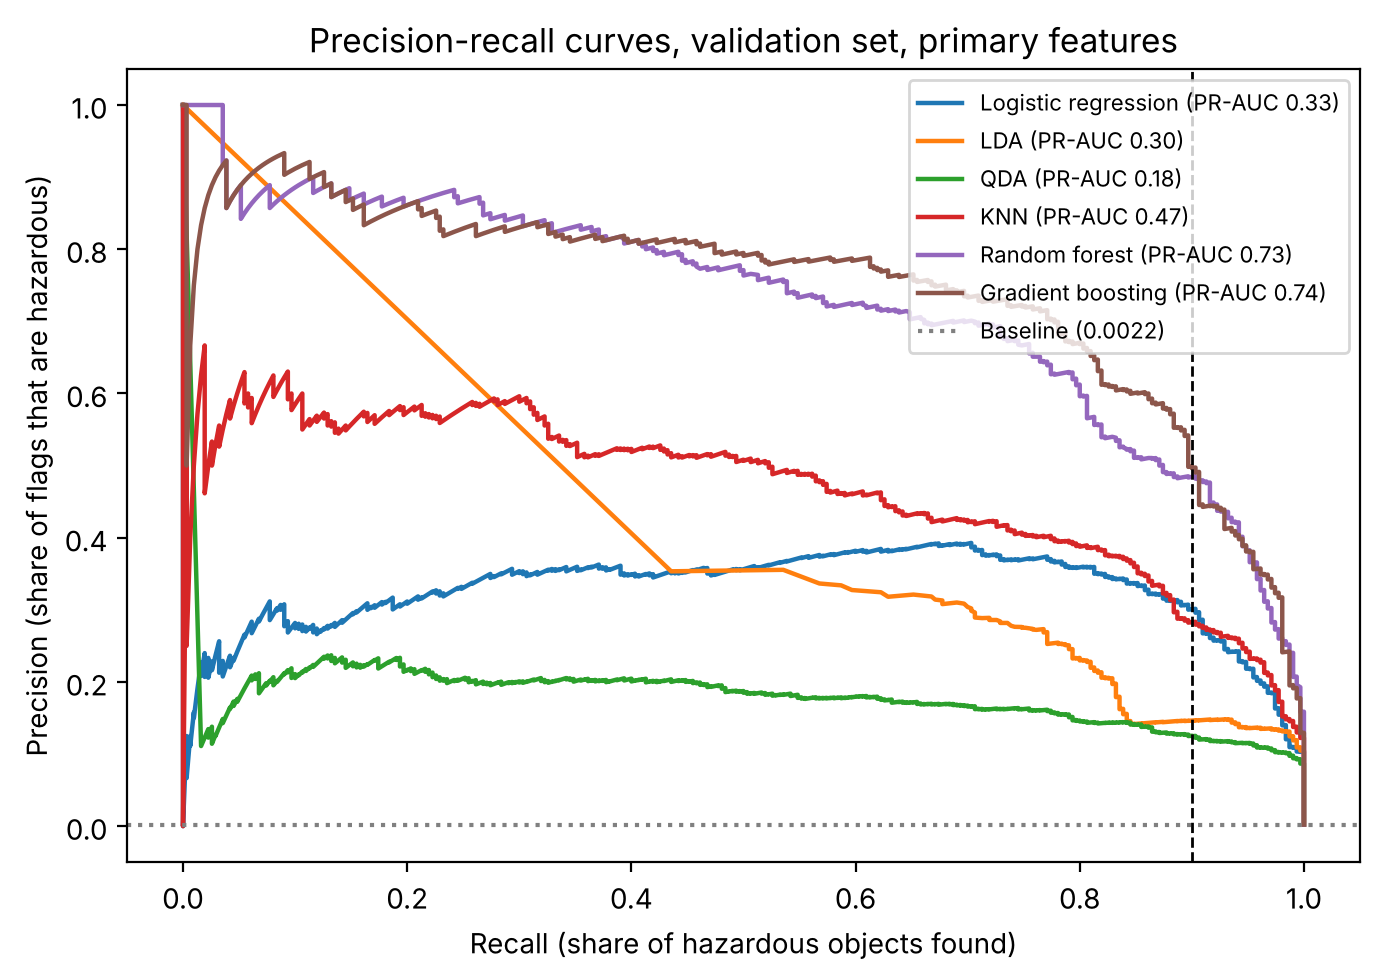

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
for name in order[1:]:
    prec, rec, _ = precision_recall_curve(y_va, VAL_PROBA[name])
    ax.plot(rec, prec, lw=1.6, label=f"{name} (PR-AUC {VAL_ROWS[name]['PR-AUC']:.2f})")
ax.axhline(y_va.mean(), ls=":", c="gray", label=f"Baseline ({y_va.mean():.4f})")
ax.axvline(RECALL_TARGET, ls="--", c="k", lw=1)
ax.set_xlabel("Recall (share of hazardous objects found)")
ax.set_ylabel("Precision (share of flags that are hazardous)")
ax.set_title("Precision-recall curves, validation set, primary features")
ax.legend(fontsize=8, loc="upper right")
save_fig("pr_curves_validation.png")

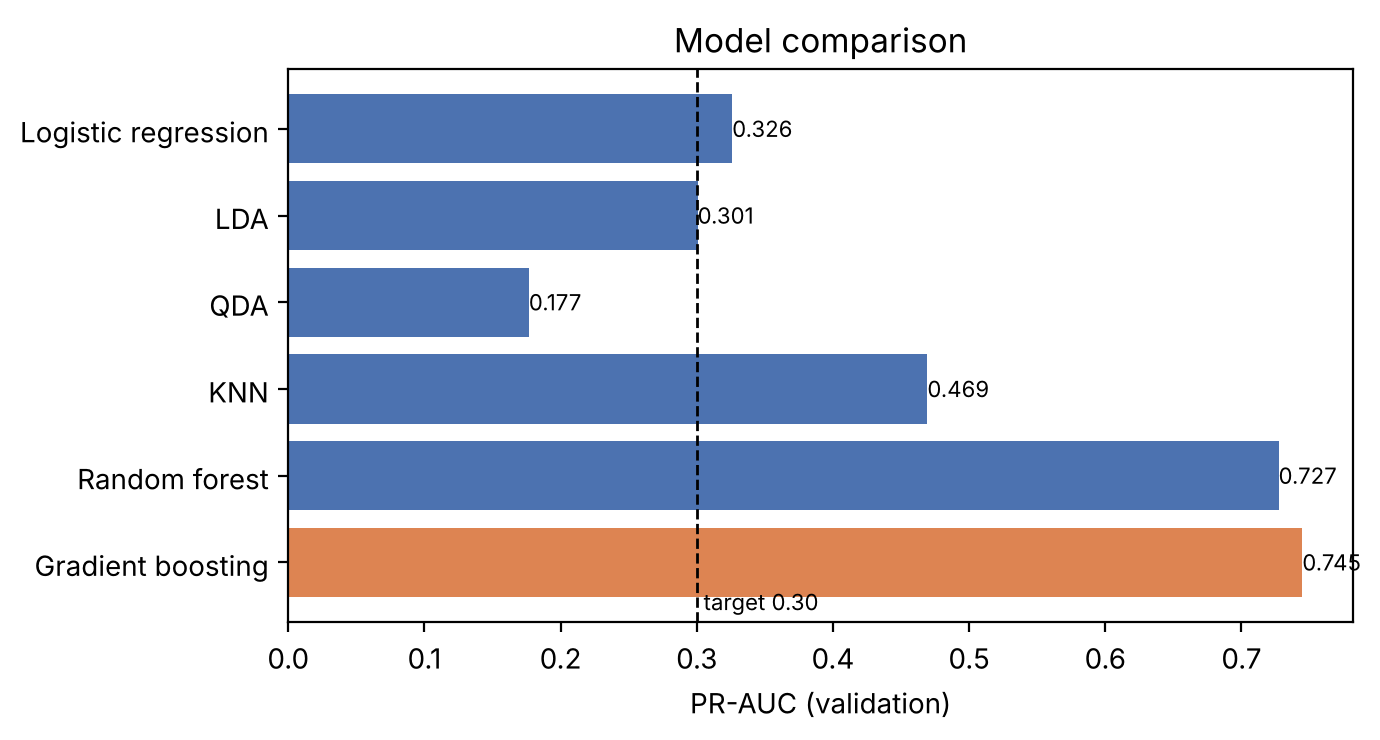

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.8))
vals = comp.loc[order[1:], "PR-AUC"].astype(float)
bars = ax.barh(vals.index, vals.values, color=["#DD8452" if n == vals.idxmax() else "#4C72B0" for n in vals.index])
ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.axvline(0.30, ls="--", c="k", lw=1)
ax.text(0.305, len(vals) - 0.45, "target 0.30", fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("PR-AUC (validation)"); ax.set_title("Model comparison")
save_fig("model_comparison.png")

**Selection rule.** Highest validation PR-AUC; ties broken by precision at the recall target. PR-AUC measures how well a
model ranks hazardous objects above the rest across all thresholds, which is what an analyst triaging a follow-up list needs.

In [18]:
tree_models = ["Random forest", "Gradient boosting"]
best_name = comp.loc[order[1:]].sort_values(["PR-AUC", "precision"], ascending=False).index[0]
best_model, best_cols = MODELS[best_name]
best_thr = VAL_ROWS[best_name]["threshold"]
print("Selected model:", best_name)
print("Threshold chosen on validation:", round(best_thr, 4))
RESULTS["selected_model"], RESULTS["threshold"] = best_name, float(best_thr)

Selected model: Gradient boosting
Threshold chosen on validation: 0.613


## 10. Threshold trade-off

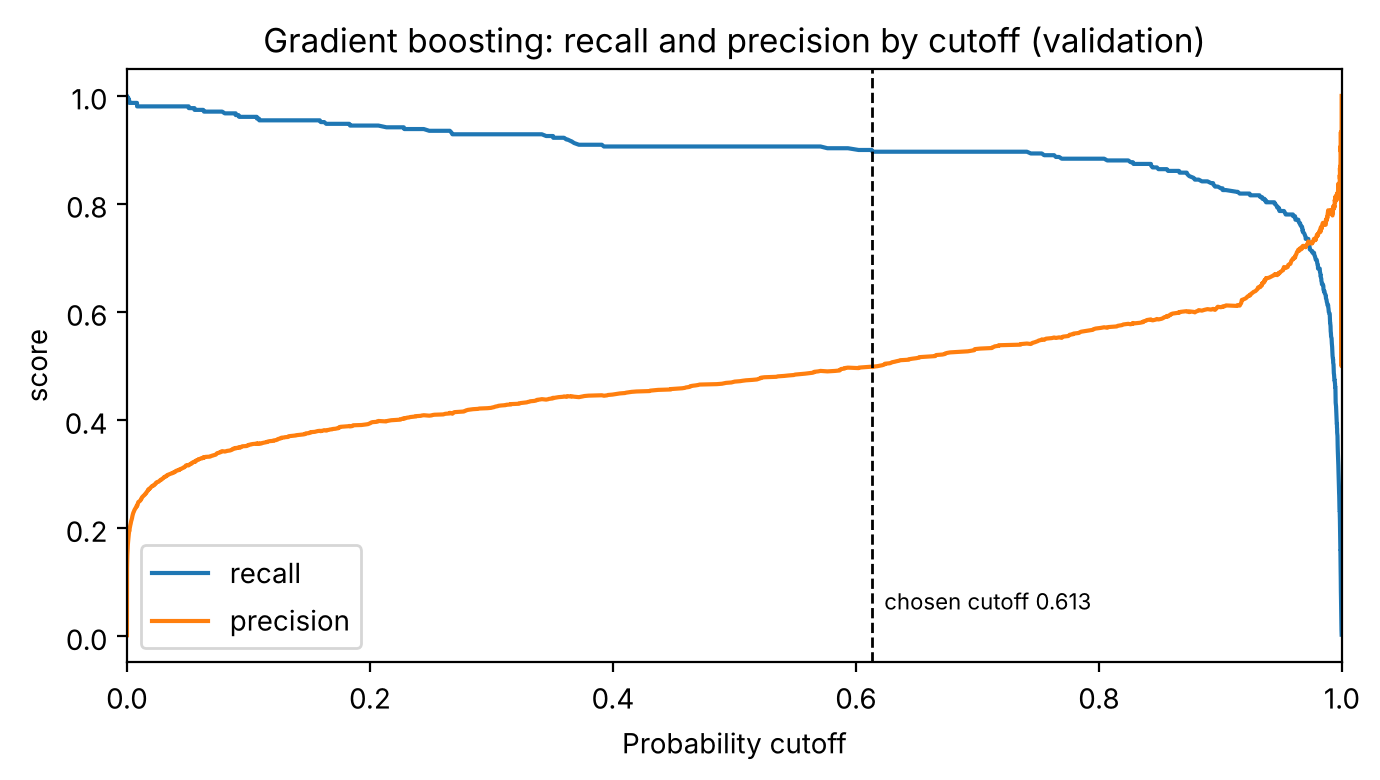

,recall target,cutoff,recall,precision,objects flagged
0,0.80,0.9451,0.8000,0.6703,370
1,0.85,0.8744,0.8516,0.6014,439
2,0.90,0.6130,0.9000,0.4991,559
3,0.95,0.1623,0.9516,0.3816,773
4,0.99,0.0019,0.9903,0.1957,1569


In [19]:
prec, rec, thr = precision_recall_curve(y_va, VAL_PROBA[best_name])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr, rec[:-1], label="recall")
ax.plot(thr, prec[:-1], label="precision")
ax.axvline(best_thr, ls="--", c="k", lw=1)
ax.text(best_thr, 0.05, f"  chosen cutoff {best_thr:.3f}", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("Probability cutoff"); ax.set_ylabel("score")
ax.set_title(f"{best_name}: recall and precision by cutoff (validation)")
ax.legend()
save_fig("threshold_tradeoff.png")

tradeoff = []
for target in [0.80, 0.85, 0.90, 0.95, 0.99]:
    t_ = threshold_for_recall(y_va, VAL_PROBA[best_name], target)
    s = scores(y_va, VAL_PROBA[best_name], t_)
    tradeoff.append({"recall target": target, "cutoff": t_, "recall": s["recall"],
                     "precision": s["precision"], "objects flagged": s["flagged"]})
tradeoff = pd.DataFrame(tradeoff)
display(tradeoff.round(4))
RESULTS["tradeoff"] = tradeoff.to_dict(orient="records")

## 11. Final evaluation on the held-out test set (run once)

Test metrics:


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged
Gradient boosting,0.6501,0.9988,0.613,0.8581,0.4448,0.5859,0.7236,598.0


95% bootstrap intervals: {'PR-AUC': (0.593, 0.709), 'recall': (0.819, 0.897), 'precision': (0.406, 0.484)}


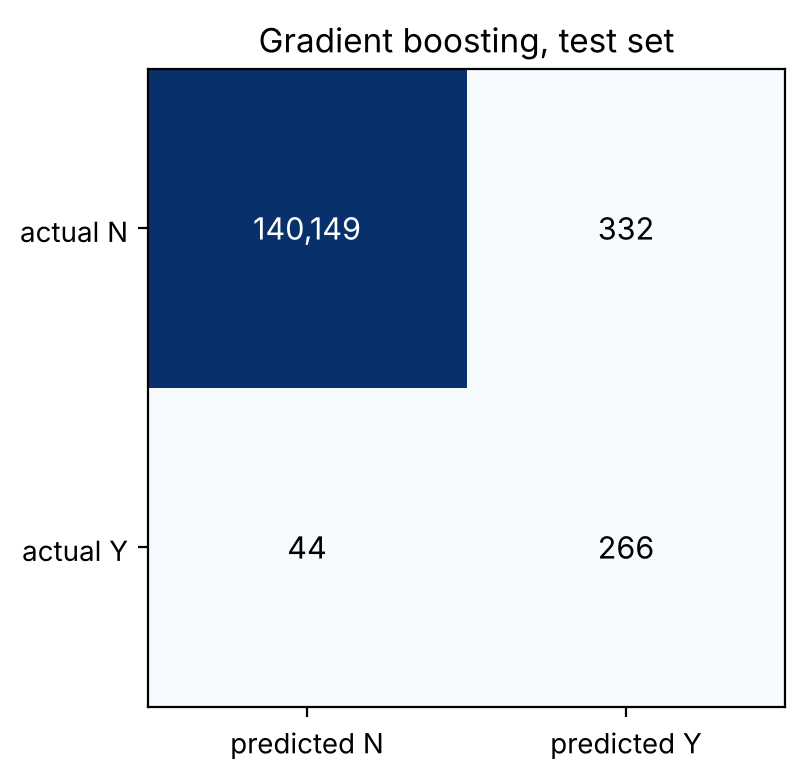

In [20]:
p_te = best_model.predict_proba(X_te[best_cols].values)[:, 1]
test = scores(y_te, p_te, best_thr)
pred_te = (p_te >= best_thr).astype(int)
cm = confusion_matrix(y_te, pred_te)
print("Test metrics:")
display(pd.Series(test).to_frame(best_name).T.round(4))

# 95% bootstrap intervals (1,000 resamples of the test set)
boot = {"PR-AUC": [], "recall": [], "precision": []}
brng = np.random.default_rng(RANDOM_STATE)
for _ in range(1000):
    b = brng.integers(0, len(y_te), len(y_te))
    yb, pb = y_te[b], p_te[b]
    boot["PR-AUC"].append(average_precision_score(yb, pb))
    boot["recall"].append(recall_score(yb, pb >= best_thr))
    boot["precision"].append(precision_score(yb, pb >= best_thr, zero_division=0))
ci = {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in boot.items()}
print("95% bootstrap intervals:", {k: tuple(round(x, 3) for x in v) for k, v in ci.items()})

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted N", "predicted Y"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["actual N", "actual Y"])
ax.set_title(f"{best_name}, test set")
save_fig("confusion_matrix_test.png")

RESULTS["test"] = {k: float(v) for k, v in test.items()}
RESULTS["test_ci"] = ci
RESULTS["test_confusion"] = cm.tolist()

In [21]:
criteria = pd.DataFrame([
    ("Recall on PHAs >= 0.90", f"{test['recall']:.3f}", test["recall"] >= 0.90),
    ("Precision >= 0.25 at chosen cutoff", f"{test['precision']:.3f}", test["precision"] >= 0.25),
    ("PR-AUC >= 0.30 and above LR and majority baselines",
     f"{test['PR-AUC']:.3f} (LR val {VAL_ROWS['Logistic regression']['PR-AUC']:.3f})",
     test["PR-AUC"] >= 0.30 and test["PR-AUC"] > VAL_ROWS["Logistic regression"]["PR-AUC"]),
], columns=["Success criterion (Milestone 1)", "Test result", "Met"])
display(criteria)
RESULTS["criteria"] = criteria.astype(str).to_dict(orient="records")

,Success criterion (Milestone 1),Test result,Met
0,Recall on PHAs >= 0.90,0.858,False
1,Precision >= 0.25 at chosen cutoff,0.445,True
2,PR-AUC >= 0.30 and above LR and majority basel...,0.650 (LR val 0.326),True


**Operating-point sensitivity (reported after selection, not used to choose anything).** The cutoff was fixed on the
validation set. With only 310 hazardous objects in each of the validation and test sets, recall at a single cutoff moves by
a few points between them, so this table shows the test result at each validation-chosen cutoff from Section 10.

In [22]:
sens = []
for row in RESULTS["tradeoff"]:
    s_ = scores(y_te, p_te, row["cutoff"])
    sens.append({"validation recall target": row["recall target"], "cutoff": row["cutoff"],
                 "test recall": s_["recall"], "test precision": s_["precision"], "test objects flagged": s_["flagged"]})
sens = pd.DataFrame(sens)
display(sens.round(4))
RESULTS["test_sensitivity"] = sens.to_dict(orient="records")

,validation recall target,cutoff,test recall,test precision,test objects flagged
0,0.80,0.9451,0.7032,0.5876,371
1,0.85,0.8744,0.7806,0.5295,457
2,0.90,0.6130,0.8581,0.4448,598
3,0.95,0.1623,0.9355,0.3384,857
4,0.99,0.0019,0.9935,0.1914,1609


### NEO subset
Every PHA is a near-Earth object, and the 915,000 non-NEOs are all negatives that are easy to reject. Scoring only the NEOs
in the test set shows how well the model separates hazardous from harmless objects **among the ones that come close**.

In [23]:
neo_te = (labeled.iloc[te_idx]["neo"] == "Y").values
neo_scores = scores(y_te[neo_te], p_te[neo_te], best_thr)
print("Highest score given to any non-NEO in the test set:", round(float(p_te[~neo_te].max()), 4),
      "| lowest score given to a test PHA:", round(float(p_te[y_te == 1].min()), 4))
print("Every flagged object is an NEO:", bool(neo_te[pred_te == 1].all()))
print(f"NEOs in test set: {neo_te.sum():,}, of which hazardous: {y_te[neo_te].sum()} "
      f"({y_te[neo_te].mean() * 100:.1f}%)")
display(pd.Series(neo_scores).to_frame("NEO subset, test").T.round(4))
RESULTS["neo_test"] = {k: float(v) for k, v in neo_scores.items()}
RESULTS["neo_test_n"] = int(neo_te.sum())

Highest score given to any non-NEO in the test set: 0.0009 | lowest score given to a test PHA: 0.0003
Every flagged object is an NEO: True
NEOs in test set: 3,500, of which hazardous: 310 (8.9%)


,PR-AUC,ROC-AUC,threshold,recall,precision,F1,F2,flagged
"NEO subset, test",0.6501,0.9479,0.613,0.8581,0.4448,0.5859,0.7236,598.0


## 12. Feature-set comparison (leakage and ablation)

The selected model type is retrained with its tuned settings on each feature set and scored on the validation set. The
test set stays untouched.

Reference (+H, +MOID) done


Primary + H done


Primary done


No uncertainty features done


No perihelion features done


,n features,PR-AUC,precision at recall 0.90,seconds
feature set,,,,
"Reference (+H, +MOID)",29,1.000,1.000,9
Primary + H,28,0.933,0.830,13
Primary,27,0.745,0.499,13
No uncertainty features,24,0.421,0.206,12
No perihelion features,13,0.615,0.409,7


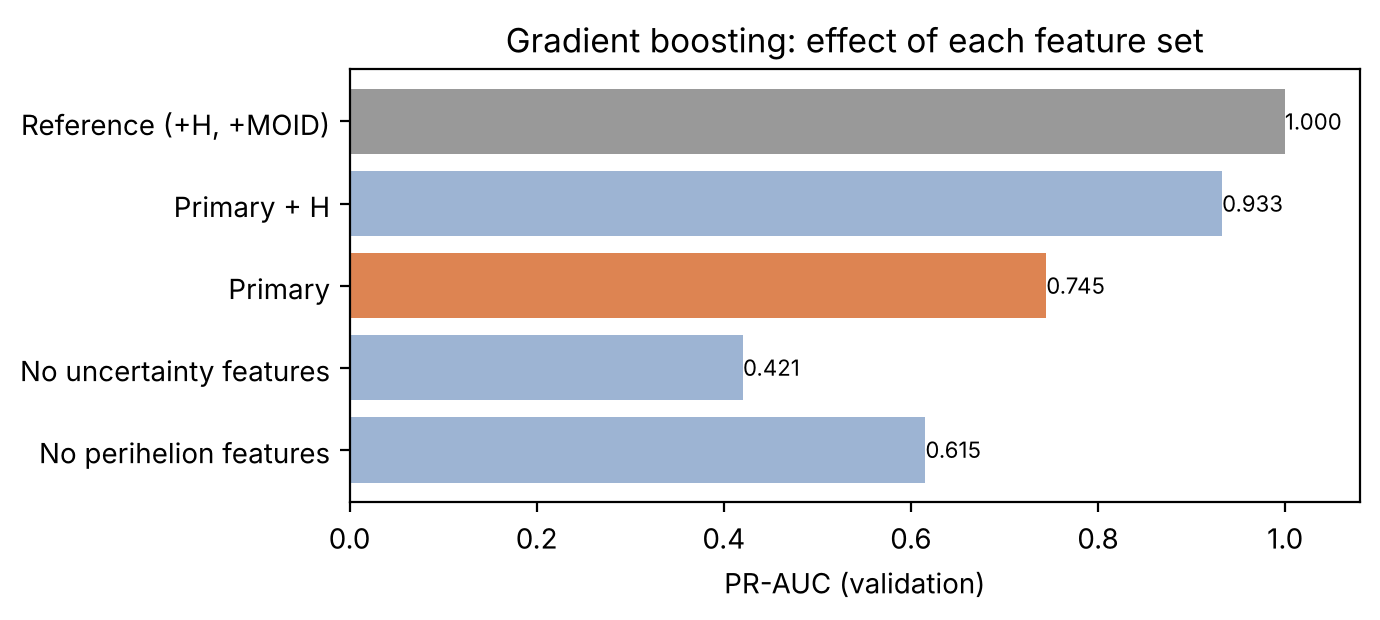

In [24]:
from sklearn.base import clone
ablation_sets = {"Reference (+H, +MOID)": REFERENCE, "Primary + H": PLUS_H, "Primary": PRIMARY,
                 "No uncertainty features": NO_UNCERTAINTY, "No perihelion features": NO_PERIHELION}
abl = []
for label, cols in ablation_sets.items():
    t = time.time()
    m = clone(best_model).fit(X_tr[cols].values, y_tr)
    p = m.predict_proba(X_va[cols].values)[:, 1]
    s = scores(y_va, p, threshold_for_recall(y_va, p))
    abl.append({"feature set": label, "n features": len(cols), "PR-AUC": s["PR-AUC"],
                "precision at recall 0.90": s["precision"], "seconds": round(time.time() - t)})
    print(label, "done")
abl = pd.DataFrame(abl).set_index("feature set")
display(abl.round(3))
RESULTS["ablation"] = abl.reset_index().to_dict(orient="records")

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(abl.index, abl["PR-AUC"], color=["#999999", "#9DB4D3", "#DD8452", "#9DB4D3", "#9DB4D3"])
ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.set_xlabel("PR-AUC (validation)")
ax.set_title(f"{best_name}: effect of each feature set")
save_fig("feature_set_comparison.png")

## 13. Interpretation

,PR-AUC drop
log_q,0.8340
log_sigma_i,0.1174
e,0.0622
i,0.0619
cos_w,0.0603
sin_w,0.0466
log_rel_sigma_a,0.0170
log_a,0.0057
cls_APO,0.0048
log_rms,0.0019


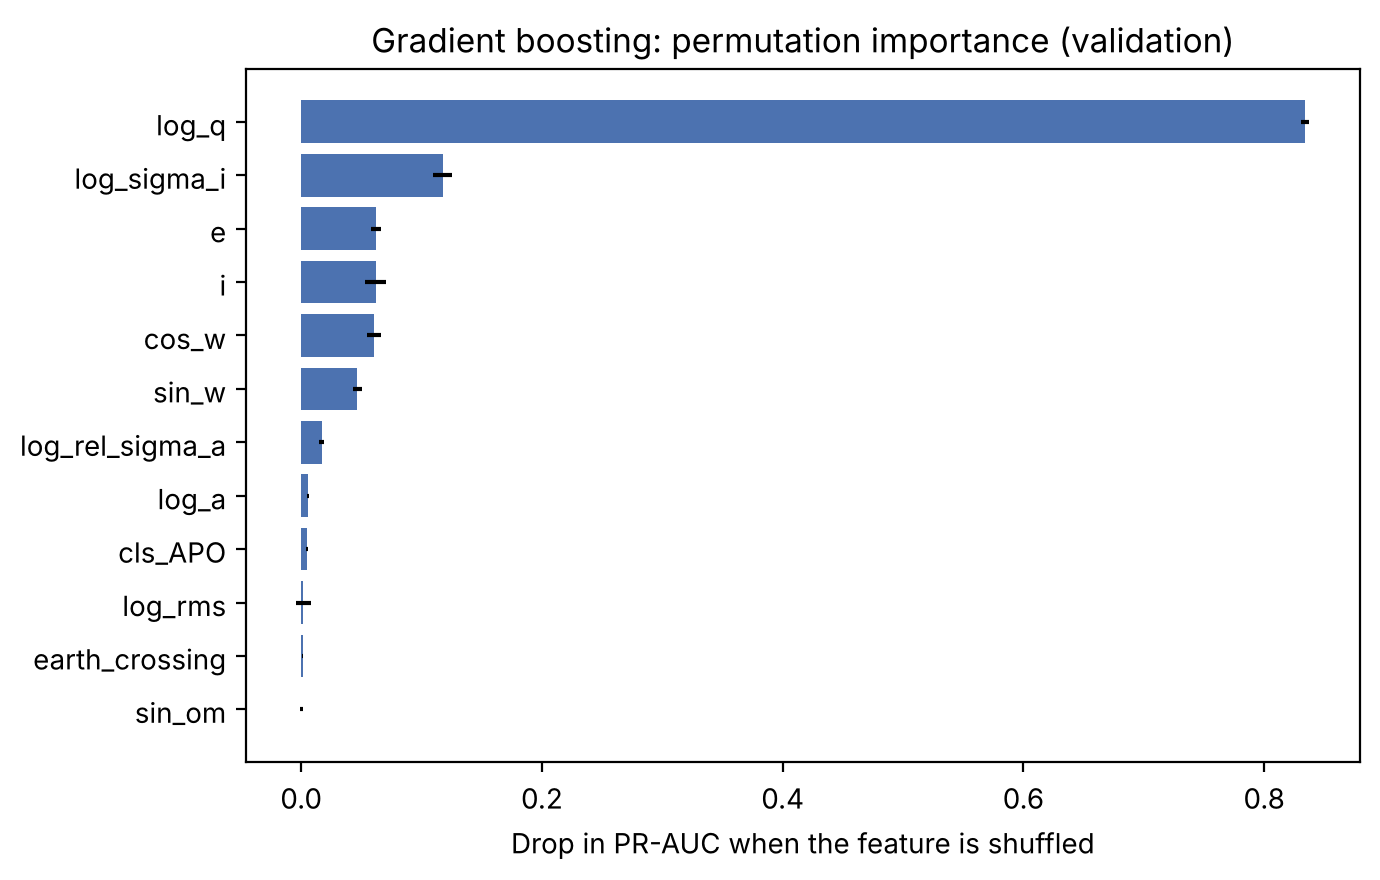

In [25]:
# Permutation importance: drop in validation PR-AUC when one feature is shuffled.
# Scored on all validation PHAs plus 40,000 other validation objects to keep run time reasonable.
prng = np.random.default_rng(RANDOM_STATE)
vrows = np.concatenate([np.where(y_va == 1)[0], prng.choice(np.where(y_va == 0)[0], 40_000, replace=False)])
pi = permutation_importance(best_model, X_va[best_cols].values[vrows], y_va[vrows],
                            scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=N_JOBS)
imp = pd.Series(pi.importances_mean, index=best_cols).sort_values(ascending=False)
display(imp.head(12).round(4).to_frame("PR-AUC drop"))
RESULTS["perm_importance"] = imp.head(12).round(4).to_dict()

top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, xerr=pd.Series(pi.importances_std, index=best_cols)[top.index], color="#4C72B0")
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title(f"{best_name}: permutation importance (validation)")
save_fig("permutation_importance.png")

In [26]:
# Logistic regression coefficients (standardized features): direction and size of each effect
lr_coef = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=LINEAR).sort_values(key=abs, ascending=False)
display(lr_coef.head(10).round(3).to_frame("standardized coefficient"))
RESULTS["lr_coef"] = lr_coef.head(10).round(3).to_dict()

,standardized coefficient
cls_AMO,0.861
earth_crossing,0.698
cls_APO,0.664
log_rel_sigma_a,-0.580
log_sigma_i,-0.479
e,0.405
log_q,-0.387
cls_MBA,-0.349
i,0.319
cos_om,0.225


Spearman correlation of log relative sigma_a with H among NEOs: 0.601


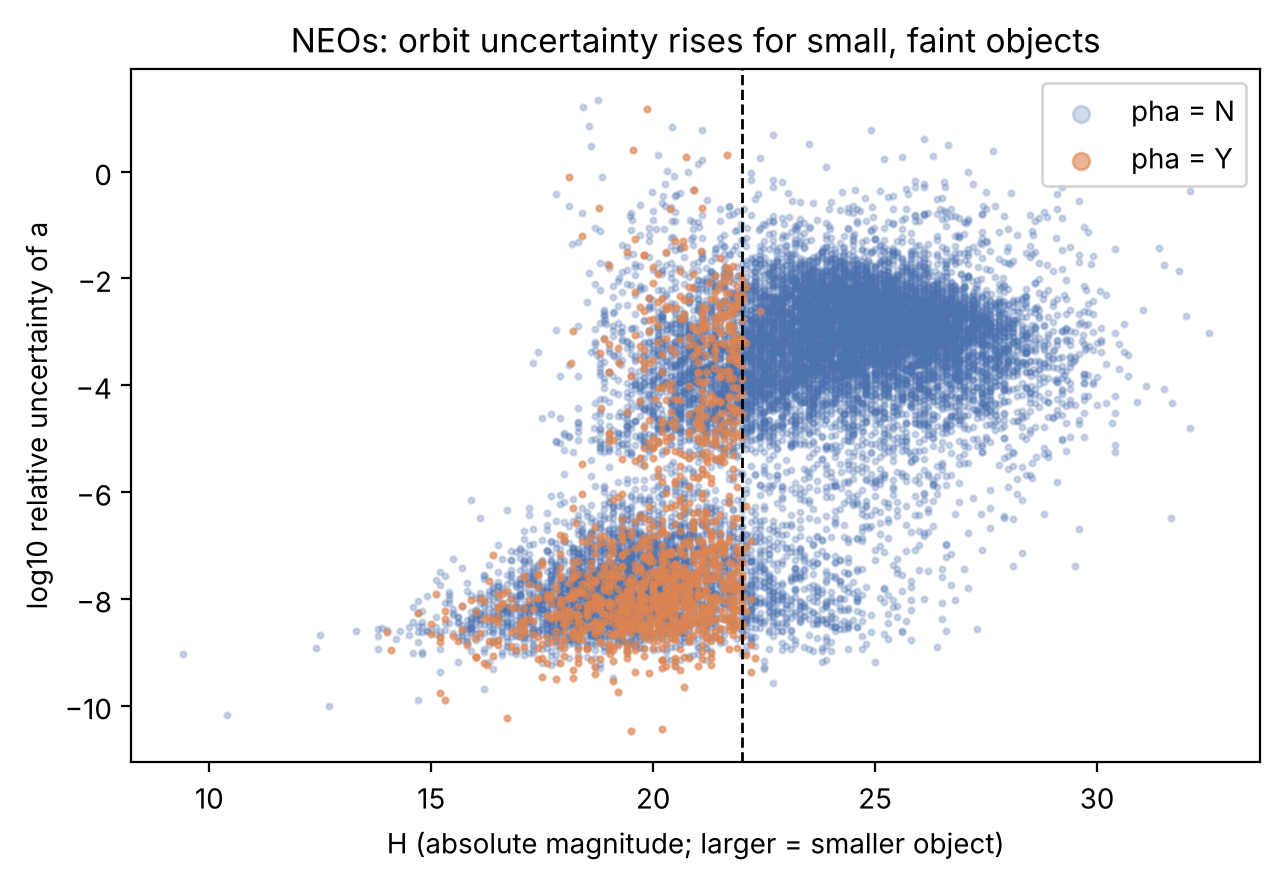

In [27]:
# Why the uncertainty feature works: orbit uncertainty tracks object brightness (H), which the model never sees
d = labeled.assign(rel_sigma=X_all["log_rel_sigma_a"].values)
neo = d[d["neo"] == "Y"]
print("Spearman correlation of log relative sigma_a with H among NEOs:",
      round(neo["rel_sigma"].corr(neo["H"], method="spearman"), 3))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
s = neo.sample(min(15000, len(neo)), random_state=RANDOM_STATE)
for lab_, color, a in [("N", "#4C72B0", 0.25), ("Y", "#DD8452", 0.6)]:
    part = s[s["pha"] == lab_]
    ax.scatter(part["H"], part["rel_sigma"], s=4, alpha=a, color=color, label=f"pha = {lab_}")
ax.axvline(22, ls="--", c="k", lw=1)
ax.set_xlabel("H (absolute magnitude; larger = smaller object)")
ax.set_ylabel("log10 relative uncertainty of a")
ax.set_title("NEOs: orbit uncertainty rises for small, faint objects")
ax.legend(markerscale=3)
save_fig("uncertainty_vs_H.png")
RESULTS["rho_relsigma_H_neo"] = float(neo["rel_sigma"].corr(neo["H"], method="spearman"))

### Error analysis: which hazardous objects does the model miss?

In [28]:
te_df = labeled.iloc[te_idx].assign(p=p_te, pred=pred_te, y=y_te)
fn, tp = te_df[(te_df.y == 1) & (te_df.pred == 0)], te_df[(te_df.y == 1) & (te_df.pred == 1)]
fp = te_df[(te_df.y == 0) & (te_df.pred == 1)]
err = pd.DataFrame({
    "missed PHAs (FN)": [len(fn), fn["H"].median(), fn["moid"].median(), fn["e"].median(), fn["class"].mode().iat[0] if len(fn) else "-"],
    "caught PHAs (TP)": [len(tp), tp["H"].median(), tp["moid"].median(), tp["e"].median(), tp["class"].mode().iat[0]],
    "false alarms (FP)": [len(fp), fp["H"].median(), fp["moid"].median(), fp["e"].median(), fp["class"].mode().iat[0] if len(fp) else "-"],
}, index=["count", "median H", "median MOID (AU)", "median e", "most common class"])
display(err)
print("False alarms by reason:")
fp_reason = pd.Series({
    "close orbit but too small (MOID <= 0.05, H > 22)": int(((fp.moid <= 0.05) & (fp.H > 22)).sum()),
    "large but orbit not close enough (MOID > 0.05)": int((fp.moid > 0.05).sum()),
})
display(fp_reason.to_frame("false alarms"))
RESULTS["errors"] = err.astype(str).to_dict()
RESULTS["fp_reason"] = fp_reason.to_dict()

,missed PHAs (FN),caught PHAs (TP),false alarms (FP)
count,44,266,332
median H,21.35,20.2,22.0
median MOID (AU),0.036134,0.022032,0.052873
median e,0.568904,0.537092,0.560391
most common class,APO,APO,APO


False alarms by reason:


,false alarms
"close orbit but too small (MOID <= 0.05, H > 22)",151
large but orbit not close enough (MOID > 0.05),178


## 14. Save results

In [29]:
RESULTS["runtime_minutes"] = round((time.time() - NOTEBOOK_START) / 60, 1)
with open("results_m2.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print("Saved results_m2.json and", len(os.listdir(FIG_DIR)), "figures in", FIG_DIR)
print("Total run time (minutes):", RESULTS["runtime_minutes"])

Saved results_m2.json and 7 figures in figures_m2
Total run time (minutes): 34.3


## 15. Summary

The written interpretation of these results is in Sections 4 to 6 of the Milestone 2 report. In short:

* The leakage-controlled model ranks hazardous objects far better than chance and than the linear models, using only orbit
  shape, orbit class and orbit-fit uncertainty.
* Giving the model MOID and H recovers the NASA rule almost perfectly, which confirms why those columns must be excluded
  from an honest evaluation.
* On the test set the model found 266 of 310 hazardous objects (recall 0.86) while flagging 598 objects in total
  (precision 0.44). Recall fell short of the 0.90 target set on validation; a lower cutoff restores it (Section 11).
* Most false alarms are near-Earth objects whose orbits do come close to Earth but that are too small to qualify: the model
  cannot see size directly, and orbit uncertainty is only a partial proxy for it.